# Databases - Basics

This tutorial covers `DataBase`, the SQLite database of `plans` for time series of environmental variables. The example is a single weather station with monthly air temperature and rainfall.

```{seealso}
The database relies on three catalogs that ship with `plans`: {doc}`variables <../variables>`, {doc}`statistics <../statistics>` and {doc}`flags <../flags>`.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans.databases import DataBase

# This avoids warnings related to uninstalled fonts
import logging
# Set the matplotlib font manager logger to only show errors (hides warnings)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# define output folder
OUTPUT_DIR = Path("outputs/databases")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved to: ./{OUTPUT_DIR}")

Outputs will be saved to: ./outputs\databases


## Describing the datasets

A database stores *records*: one value at one time. Each record belongs to a *spec*, which describes a dataset: what variable it measures, which statistic summarizes each value over the time step, and where the data comes from. These three fields point to the catalogs by name.

Spec names are uppercase, with letters, digits and `_`. Here, a monthly mean temperature and a monthly rainfall total:

In [2]:
specs = [
    {
        "name": "TAS_MONTHLY",
        "abstract": "Monthly mean air temperature at the station (synthetic)",
        "method": "mean of daily readings",
        "timestep": "1M",
        "extent": "station",
        "scale": 1,
        "offset": 0,
        "start": "2001-01-01",
        "end": None,
        "variable_name": "surface air temperature",
        "statistic_name": "mean",
        "source_name": "INMET",
    },
    {
        "name": "PPT_MONTHLY",
        "abstract": "Monthly rainfall total at the station (synthetic)",
        "method": "sum of daily readings",
        "timestep": "1M",
        "extent": "station",
        "scale": 1,
        "offset": 0,
        "start": "2001-01-01",
        "end": None,
        "variable_name": "precipitation",
        "statistic_name": "sum",
        "source_name": "INMET",
    },
]
file_specs = OUTPUT_DIR / "station_specs.json"
file_specs.write_text(json.dumps(specs, indent=2), encoding="utf-8")
print(f"Specs saved to: ./{file_specs}")

Specs saved to: ./outputs\databases\station_specs.json


## Creating the database

The `.new()` method creates the file from a setup. The setup is a dict, or a TOML or JSON file with the same structure. It needs the path of the database and the path of the specs file. Catalogs come from `plans` unless the setup points to other files. With `overwrite=True`, an existing file is replaced, so this notebook can run again:

In [3]:
db = DataBase(name="Station")
file_db = db.new(
    config={
        "database": {"path": str(OUTPUT_DIR / "station.db")},
        "specs": {"path": str(file_specs)},
    },
    overwrite=True,
)
print(db.inspect_schema(quiet=True))

[Station]
  records  (0 rows)                   specs  (2 rows)                     flags  (10 rows)                  
    id                   INTEGER        id                   INTEGER        id                   INTEGER    
    inserted             INTEGER        name                 TEXT           name                 TEXT       
    datetime             INTEGER        abstract             TEXT           abstract             TEXT       
    value                REAL           method               TEXT           alias                TEXT       
    flag_value           INTEGER        timestep             TEXT           value                INTEGER    
    spec_id              INTEGER        extent               TEXT                                           
                                        scale                REAL                                           
                                        offset               REAL                                           
         

Larger projects often keep the setup in a file, and pass its path instead: `db.new(config="station_setup.toml")`. This setup, as a file:

`````{tab-set}
:sync-group: setup

````{tab-item} TOML
:sync: toml

```toml
[database]
path = "outputs/databases/station.db"

[specs]
path = "outputs/databases/station_specs.json"
```
````

````{tab-item} JSON
:sync: json

```json
{
  "database": {"path": "outputs/databases/station.db"},
  "specs": {"path": "outputs/databases/station_specs.json"}
}
```
````
`````

Relative paths follow the working directory, not the setup file. Both formats refuse single backslashes, so Windows paths are written with forward slashes.

The database is now connected. The catalogs are plain tables, so SQL works on them. The units and the valid domain of each variable come from the `variables` table:

In [4]:
db.query_sql(
    sql="SELECT code, name, units, domain FROM variables WHERE name IN (?, ?)",
    params=["surface air temperature", "precipitation"],
)

,code,name,units,domain
0,CLM100,precipitation,mm/(dt),[0U)
1,CLM001,surface air temperature,degC,(U)


In [5]:
print(db.inspect_specs(quiet=True))

[Station — specs]

  TAS_MONTHLY  (id 1)
       surface air temperature · mean · 1M · station
       source: INMET
       period: 2001-01-01 → open
       method: mean of daily readings
       Monthly mean air temperature at the station (synthetic)

  PPT_MONTHLY  (id 2)
       precipitation · sum · 1M · station
       source: INMET
       period: 2001-01-01 → open
       method: sum of daily readings
       Monthly rainfall total at the station (synthetic)



## Sample data

Lets make 20 years of monthly data. Temperature follows a seasonal cycle, warmer in January, as in the southern hemisphere. Rainfall is drawn from a gamma distribution whose mean also changes with the season:

In [6]:
rng = np.random.default_rng(seed=42)  # ensure reproducibility

dates = pd.date_range(start="2001-01-01", end="2020-12-01", freq="MS")
season = np.cos(2 * np.pi * (dates.month - 1) / 12)

df_tas = pd.DataFrame(
    {"datetime": dates, "value": 19 + 5 * season + rng.normal(scale=1, size=len(dates))}
)
mean_ppt = 120 - 30 * season
df_ppt = pd.DataFrame(
    {"datetime": dates, "value": rng.gamma(shape=4, scale=mean_ppt / 4)}
)
df_ppt.head()

,datetime,value
0,2001-01-01,50.194364
1,2001-02-01,28.809903
2,2001-03-01,247.847522
3,2001-04-01,58.258278
4,2001-05-01,422.441777


Real data is never this clean. Lets add two problems to the rainfall: a month the station did not report, and a negative value from a faulty sensor:

In [7]:
df_ppt.loc[30, "value"] = np.nan
df_ppt.loc[90, "value"] = -12.0
df_ppt.loc[[30, 90]]

,datetime,value
30,2003-07-01,NaN
90,2008-07-01,-12.0


## Inserting records

The `.insert_records()` method takes a `DataFrame` with `datetime` and `value` columns, the spec name, and a flag for the batch. Flag `1` is `regular`. Dates can be text or datetimes; they are stored as epoch seconds:

In [8]:
db.insert_records(dataframe=df_tas, spec_name="TAS_MONTHLY", flag=1)

For the rainfall, two things happen. Missing values are dropped by default; with `nan_policy="void"`, they are stored as an empty value with the `void` flag (`0`), so the gap reported by the station is kept. And values outside the domain of the variable, `[0U)` for precipitation, turn from `regular` into `suspect` (`2`), with a warning. The value is kept for review:

In [9]:
import warnings

# catch the warning here only to print its message
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    db.insert_records(dataframe=df_ppt, spec_name="PPT_MONTHLY", flag=1, nan_policy="void")
for warning in caught:
    print(f"{warning.category.__name__}: {warning.message}")

In [10]:
print(db.inspect_records(head=5, quiet=True))

[Station]
  records  (480 rows)
    id                   INTEGER
    inserted             INTEGER
    datetime             INTEGER
    value                REAL
    flag_value           INTEGER
    spec_id              INTEGER

  head (5)
 id         inserted         datetime     value  flag_value  spec_id
  1 2026-11-06 21:03 2001-01-01 00:00 24.304717           1        1
  2 2026-11-06 21:03 2001-02-01 00:00 22.290143           1        1
  3 2026-11-06 21:03 2001-03-01 00:00 22.250451           1        1
  4 2026-11-06 21:03 2001-04-01 00:00 19.940565           1        1
  5 2026-11-06 21:03 2001-05-01 00:00 14.548965           1        1



## Querying records

The `.query_records()` method takes all filters and options in one dict. By default, it returns the long format, one row per record, with `datetime` as a UTC timestamp:

In [11]:
df = db.query_records(
    query_dict={"spec_name": "PPT_MONTHLY", "start": "2003-01-01", "end": "2003-12-31"}
)
df[["datetime", "value", "flag_value", "spec_name"]]

,datetime,value,flag_value,spec_name
0,2003-01-01 00:00:00+00:00,94.391632,1,PPT_MONTHLY
1,2003-02-01 00:00:00+00:00,73.691661,1,PPT_MONTHLY
2,2003-03-01 00:00:00+00:00,84.131814,1,PPT_MONTHLY
3,2003-04-01 00:00:00+00:00,218.032488,1,PPT_MONTHLY
4,2003-05-01 00:00:00+00:00,109.065666,1,PPT_MONTHLY
5,2003-06-01 00:00:00+00:00,155.584754,1,PPT_MONTHLY
6,2003-07-01 00:00:00+00:00,NaN,0,PPT_MONTHLY
7,2003-08-01 00:00:00+00:00,294.463555,1,PPT_MONTHLY
8,2003-09-01 00:00:00+00:00,188.391552,1,PPT_MONTHLY
9,2003-10-01 00:00:00+00:00,106.514657,1,PPT_MONTHLY


Flags select records. Here, the records that need attention:

In [12]:
df = db.query_records(query_dict={"flag_value": [0, 2]})
df[["datetime", "value", "flag_value", "spec_name"]]

,datetime,value,flag_value,spec_name
0,2003-07-01 00:00:00+00:00,NaN,0,PPT_MONTHLY
1,2008-07-01 00:00:00+00:00,-12.0,2,PPT_MONTHLY


The wide format has one column per spec, indexed by `datetime`. With `with_meta`, the variable, units, statistic and source of each spec go to `.attrs["specs"]`. Selecting only `regular` records leaves the gap and the suspect month empty:

In [13]:
wide = db.query_records(
    query_dict={
        "spec_name": ["TAS_MONTHLY", "PPT_MONTHLY"],
        "flag_value": 1,
        "wide": True,
        "with_meta": True,
    }
)
wide.head()

spec_name,TAS_MONTHLY,PPT_MONTHLY
datetime,,
2001-01-01 00:00:00+00:00,24.304717,50.194364
2001-02-01 00:00:00+00:00,22.290143,28.809903
2001-03-01 00:00:00+00:00,22.250451,247.847522
2001-04-01 00:00:00+00:00,19.940565,58.258278
2001-05-01 00:00:00+00:00,14.548965,422.441777


In [14]:
meta = wide.attrs["specs"].set_index("spec_name")
meta

,variable_name,units,statistic_name,source_name
spec_name,,,,
TAS_MONTHLY,surface air temperature,degC,mean,INMET
PPT_MONTHLY,precipitation,mm/(dt),sum,INMET


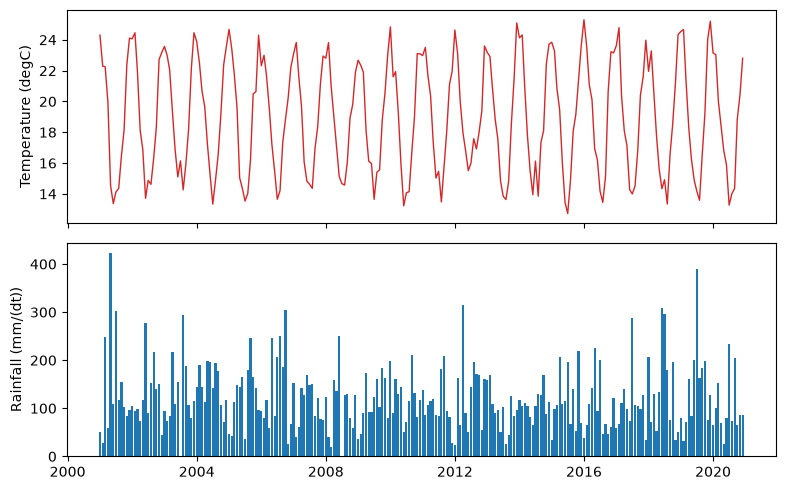

In [15]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(8, 5), sharex=True)
axes[0].plot(wide.index, wide["TAS_MONTHLY"], color="tab:red", lw=1)
axes[0].set_ylabel(f'Temperature ({meta.loc["TAS_MONTHLY", "units"]})')
axes[1].bar(wide.index, wide["PPT_MONTHLY"], width=25, color="tab:blue")
axes[1].set_ylabel(f'Rainfall ({meta.loc["PPT_MONTHLY", "units"]})')
plt.tight_layout()
plt.show()

As a `DataFrame`, the result goes straight into `pandas`. The mean year:

In [16]:
wide.groupby(wide.index.month).mean().round(1)

spec_name,TAS_MONTHLY,PPT_MONTHLY
datetime,,
1,23.7,98.1
2,23.3,84.3
3,21.2,110.6
4,19.0,133.7
5,16.4,140.4
6,14.7,133.7
7,14.4,175.6
8,14.4,145.6
9,16.3,151.2


## Closing and reopening

The `.close()` method releases the file. Later, `.connect()` opens it again, with all the records in place:

In [17]:
db.close()

db = DataBase(name="Station")
db.connect(file_db=file_db)
print(len(db.query_records()), "records")
db.close()

480 records
